<a href="https://colab.research.google.com/github/Joel-Vijo/intro_to_git/blob/master/cpu_vs_gpu_monte_carlo_var.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CPU vs GPU: Monte Carlo Value-at-Risk

**Goal:** show *when* and *why* a GPU beats a CPU, using a workload from finance: portfolio VaR via correlated Monte Carlo.

**Plan**
1. Define the simulation once, written so the *same code* runs on NumPy (CPU) and CuPy (GPU)
2. Check correctness (both give the same VaR within Monte Carlo error)
3. Benchmark: runtime vs. number of scenarios, assets, and horizon
4. Look at where the GPU does **not** help (small sizes, transfer overhead)
5. Float32 vs float64

> **Colab setup:** `Runtime -> Change runtime type -> T4 GPU`, then `Runtime -> Run all`.
> The notebook still runs on CPU-only runtimes (GPU sections are skipped).

## 0. Setup

In [1]:
import subprocess, time, math, random, statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import cupy as cp
    HAS_GPU = cp.cuda.runtime.getDeviceCount() > 0   # CuPy can be installed yet see zero devices
    if not HAS_GPU:
        print("CuPy is installed but reports 0 CUDA devices.")
except Exception as e:
    cp = None
    HAS_GPU = False
    print("No usable GPU/CuPy found:", e)

print("NumPy:", np.__version__)
if HAS_GPU:
    props = cp.cuda.runtime.getDeviceProperties(0)
    print("CuPy :", cp.__version__)
    print("GPU  :", props["name"].decode(), f"| {props['totalGlobalMem']/1e9:.1f} GB")
else:
    print("Switch the Colab runtime to a GPU to see the comparison.")

import os
print("CPU cores available:", os.cpu_count())

NumPy: 2.4.6
CuPy : 14.0.1
GPU  : Tesla T4 | 15.6 GB
CPU cores available: 2


## 1. The workload

We simulate `n_scen` scenarios of `horizon` daily returns for `n_assets` correlated assets:

1. Build a covariance matrix and take its **Cholesky factor** `L`
2. Draw independent normals `Z`, correlate them: `R = Z @ L.T + mu`
3. Convert returns to per-asset P&L with a nonlinear transform (`expm1`), so the work can't be algebraically collapsed into a single vector
4. Portfolio P&L per scenario = weighted sum over assets, summed over the horizon
5. **VaR** = the loss at the `alpha` quantile, **CVaR** = mean loss beyond it

Every scenario is independent, so this is *embarrassingly parallel*: ideal for a GPU.

The function takes `xp` (either `numpy` or `cupy`). **The algorithm is identical; only where it runs changes.**
Scenarios are processed in chunks so that large runs fit in memory.

In [2]:
def make_portfolio(n_assets, seed=42, dtype=np.float32):
    # Built on the host in float64 for determinism, then cast. Same inputs for CPU and GPU.
    rng = np.random.default_rng(seed)
    B = rng.standard_normal((n_assets, 5))                  # 5 latent risk factors
    cov = B @ B.T + np.diag(rng.uniform(0.5, 1.5, n_assets))
    d = np.sqrt(np.diag(cov))
    corr = cov / np.outer(d, d)
    vol = rng.uniform(0.01, 0.03, n_assets)                  # 1-3% daily vol
    cov = corr * np.outer(vol, vol)
    L = np.linalg.cholesky(cov)
    mu = rng.uniform(-0.0002, 0.0005, n_assets)
    w = np.full(n_assets, 1.0 / n_assets)
    return L.astype(dtype), mu.astype(dtype), w.astype(dtype)


CHUNK_BYTES = 600e6   # size of ONE chunk-sized array (Z). Lower this if you hit out-of-memory errors.

def estimate_peak_bytes(n_scen, n_assets, horizon=1, dtype=np.float32, chunk_bytes=CHUNK_BYTES):
    item = np.dtype(dtype).itemsize
    chunk = min(n_scen, max(1, int(chunk_bytes // (n_assets * horizon * item))))
    per_chunk = chunk * horizon * n_assets * item
    # Z, the matmul output, R (= matmul + mu) and asset_pnl can coexist: ~4 chunk-sized arrays,
    # plus the pnl vector and the copy that partition() makes.
    return 4 * per_chunk + 2 * n_scen * item


def var_mc(xp, L, mu, w, n_scen, horizon=1, alpha=0.01, seed=0,
           dtype=np.float32, chunk_bytes=CHUNK_BYTES):
    # L, mu, w must already live on the device that xp refers to.
    if not (0.0 < alpha < 1.0):
        raise ValueError(f"alpha must be strictly between 0 and 1, got {alpha}")
    n_assets = L.shape[0]
    item = np.dtype(dtype).itemsize

    est = estimate_peak_bytes(n_scen, n_assets, horizon, dtype, chunk_bytes)
    if xp is not np:                                   # GPU: fail early with a clear message
        free = xp.cuda.runtime.memGetInfo()[0]
        if est > 0.9 * free:
            raise MemoryError(f"Estimated peak {est/1e9:.1f} GB vs {free/1e9:.1f} GB free on the GPU. "
                              f"Lower CHUNK_BYTES or n_scen.")

    rng = xp.random.default_rng(seed)
    chunk = max(1, int(chunk_bytes // (n_assets * horizon * item)))
    pnl = xp.empty(n_scen, dtype=dtype)
    LT = L.T.copy()
    for s in range(0, n_scen, chunk):
        m = min(chunk, n_scen - s)
        Z = rng.standard_normal((m * horizon, n_assets), dtype=dtype)   # random numbers made ON the device
        R = Z @ LT + mu                                                  # correlate (big matmul)
        asset_pnl = xp.expm1(R)                                          # nonlinear transform
        daily = asset_pnl @ w                                            # portfolio daily P&L
        pnl[s:s + m] = daily.reshape(m, horizon).sum(axis=1)
    k = int(alpha * n_scen)
    q = xp.partition(pnl, k)[k]                                          # alpha-quantile without a full sort
    var = -q
    cvar = -pnl[pnl <= q].mean()
    return float(var), float(cvar)

### Memory sizing

`CHUNK_BYTES` sets the size of **one** chunk-sized array, but several arrays of that size are alive at once (`Z`, the matmul output, `R`, `asset_pnl`), plus the full `pnl` vector and the copy `partition()` makes. The model below therefore estimates peak allocation as roughly **4 x chunk + 2 x n_scen** elements. `var_mc` checks the estimate against free GPU memory before allocating and raises a clear error instead of crashing mid-run.

In [3]:
for n_s, a, h in [(1_000_000, 100, 1), (10_000_000, 100, 1), (100_000_000, 100, 1), (100_000, 100, 250), (1_000_000, 1000, 1)]:
    est = estimate_peak_bytes(n_s, a, h)
    print(f"{n_s:>12,} scenarios x {a:>4} assets x {h:>3} days -> estimated peak ~ {est/1e9:5.2f} GB")
if HAS_GPU:
    free, total = cp.cuda.runtime.memGetInfo()
    print(f"\nGPU memory: {free/1e9:.1f} GB free of {total/1e9:.1f} GB")

   1,000,000 scenarios x  100 assets x   1 days -> estimated peak ~  1.61 GB
  10,000,000 scenarios x  100 assets x   1 days -> estimated peak ~  2.48 GB
 100,000,000 scenarios x  100 assets x   1 days -> estimated peak ~  3.20 GB
     100,000 scenarios x  100 assets x 250 days -> estimated peak ~  2.40 GB
   1,000,000 scenarios x 1000 assets x   1 days -> estimated peak ~  2.41 GB

GPU memory: 15.5 GB free of 15.6 GB


## 2. Correctness check
Before timing anything, verify CPU and GPU agree. They use different random number generators, so we expect agreement within Monte Carlo error, not bit-for-bit equality. A single run per device can't show that, so we repeat with independent seeds and report the mean difference with a 95% confidence interval.

In [4]:
N_ASSETS_CHECK, N_SCEN_CHECK, N_TRIALS = 100, 500_000, 10
L, mu, w = make_portfolio(N_ASSETS_CHECK)

cpu_vars = np.array([var_mc(np, L, mu, w, N_SCEN_CHECK, seed=s)[0] for s in range(N_TRIALS)])
print(f"CPU: mean VaR(99%) = {cpu_vars.mean():.5f}   (std across seeds {cpu_vars.std(ddof=1):.5f}, {N_TRIALS} trials)")

if HAS_GPU:
    Lg, mug, wg = cp.asarray(L), cp.asarray(mu), cp.asarray(w)
    gpu_vars = np.array([var_mc(cp, Lg, mug, wg, N_SCEN_CHECK, seed=1000 + s)[0] for s in range(N_TRIALS)])
    print(f"GPU: mean VaR(99%) = {gpu_vars.mean():.5f}   (std across seeds {gpu_vars.std(ddof=1):.5f}, {N_TRIALS} trials)")

    # The two devices use different RNG streams, so the two samples are independent: Welch-style CI on the difference of means.
    diff = gpu_vars.mean() - cpu_vars.mean()
    v_c, v_g = cpu_vars.var(ddof=1) / N_TRIALS, gpu_vars.var(ddof=1) / N_TRIALS
    se = np.sqrt(v_c + v_g)
    try:
        from scipy import stats
        df_w = (v_c + v_g) ** 2 / (v_c ** 2 / (N_TRIALS - 1) + v_g ** 2 / (N_TRIALS - 1))
        tcrit = stats.t.ppf(0.975, df_w)
    except Exception:
        tcrit = 2.1
    lo, hi = diff - tcrit * se, diff + tcrit * se
    print(f"GPU - CPU VaR difference: {diff:+.6f}   95% CI [{lo:+.6f}, {hi:+.6f}]   ({diff / cpu_vars.mean():+.3%} of CPU VaR)")
    if lo <= 0 <= hi:
        print("The CI contains 0: no systematic CPU/GPU difference detectable at this sample size.")
    else:
        print("The CI excludes 0: look closer (a tiny RNG-related bias is possible; check the size relative to VaR).")
    assert abs(diff) / cpu_vars.mean() < 0.02, "CPU and GPU VaR disagree more than expected"

    est = estimate_peak_bytes(N_SCEN_CHECK, N_ASSETS_CHECK)
    pool = cp.get_default_memory_pool()
    print(f"Memory: estimated peak {est/1e9:.2f} GB | CuPy memory pool currently holds {pool.total_bytes()/1e9:.2f} GB")

CPU: mean VaR(99%) = 0.00321   (std across seeds 0.00001, 10 trials)
GPU: mean VaR(99%) = 0.00321   (std across seeds 0.00001, 10 trials)
GPU - CPU VaR difference: +0.000004   95% CI [-0.000003, +0.000011]   (+0.136% of CPU VaR)
The CI contains 0: no systematic CPU/GPU difference detectable at this sample size.
Memory: estimated peak 0.80 GB | CuPy memory pool currently holds 0.61 GB


## 3. The strawman: pure Python loops

Included only to show the worst case. It is **not** a fair baseline. The fair CPU baseline is vectorized NumPy (which also uses multithreaded BLAS for the matmul).

In [5]:
def var_pure_python(L, mu, w, n_scen, alpha=0.01, seed=0):
    rnd = random.Random(seed)
    n = len(mu)
    Ll, mul, wl = L.tolist(), mu.tolist(), w.tolist()
    pnl = []
    for _ in range(n_scen):
        z = [rnd.gauss(0, 1) for _ in range(n)]
        total = 0.0
        for i in range(n):
            r = mul[i] + sum(Ll[i][j] * z[j] for j in range(i + 1))
            total += wl[i] * math.expm1(r)
        pnl.append(total)
    pnl.sort()
    return -pnl[int(alpha * n_scen)]

A_small, N_small = 50, 5_000
Ls, mus, ws = make_portfolio(A_small)

t = time.perf_counter(); v_py = var_pure_python(Ls, mus, ws, N_small); t_py = time.perf_counter() - t
t = time.perf_counter(); v_np, _ = var_mc(np, Ls, mus, ws, N_small); t_np = time.perf_counter() - t
print(f"Pure Python: {t_py:.3f}s   NumPy: {t_np:.5f}s   -> NumPy is {t_py/t_np:,.0f}x faster")
print(f"(5,000 scenarios x 50 assets. At 10 million scenarios pure Python would need ~{t_py*10_000_000/N_small/3600:.1f} hours)")

Pure Python: 0.687s   NumPy: 0.00620s   -> NumPy is 111x faster
(5,000 scenarios x 50 assets. At 10 million scenarios pure Python would need ~0.4 hours)


## 4. Benchmark harness

Two things people commonly get wrong with GPU benchmarks, handled here:

- **Asynchronous execution:** GPU calls return immediately. We call `synchronize()` before stopping the clock, otherwise we'd time the *launch*, not the *work*.
- **Warm-up:** the first GPU call pays for CUDA context creation and kernel compilation, so we run a small throwaway call first.

We report the **median of several runs** together with min/max and the interquartile range (IQR, shaded in the plots), because small workloads and shared Colab resources are noisy.

**Two benchmark modes**
- `kernel` (default): portfolio construction and the host-to-device copy of `L`, `mu`, `w` happen *outside* the timed region. This measures simulation throughput, which is the right number when you run many simulations on the same portfolio.
- `end_to_end`: portfolio construction, host-to-device copy, the simulation and returning the result are all timed. This is closer to the latency of one complete application call. (One-time CUDA initialization is still excluded via warm-up.)

In [6]:
def sync():
    if HAS_GPU:
        cp.cuda.Stream.null.synchronize()

def timeit_stats(fn, reps=3):
    times = []
    for _ in range(reps):
        sync()
        t = time.perf_counter()
        fn()
        sync()
        times.append(time.perf_counter() - t)
    t = np.array(times)
    return {"median": float(np.median(t)), "min": float(t.min()), "max": float(t.max()),
            "q1": float(np.percentile(t, 25)), "q3": float(np.percentile(t, 75))}

def timeit(fn, reps=3):
    return timeit_stats(fn, reps)["median"]

def choose_reps(work):
    # more repeats where runs are cheap and noisy, fewer where each run is slow
    return 9 if work < 1e7 else 5 if work < 1e9 else 3 if work < 1e10 else 1

def bench(n_scen, n_assets, horizon=1, run_cpu=True, run_gpu=True, dtype=np.float32, mode="kernel"):
    # mode="kernel"     : portfolio built / copied to the device OUTSIDE the timed region
    # mode="end_to_end" : portfolio construction + host->device copy + simulation + result are all timed
    assert mode in ("kernel", "end_to_end")
    reps = choose_reps(n_scen * n_assets * horizon)
    row = {"mode": mode, "n_scen": n_scen, "n_assets": n_assets, "horizon": horizon, "reps": reps}
    L, mu, w = make_portfolio(n_assets, dtype=dtype)

    if run_cpu:
        if mode == "kernel":
            fn = lambda: var_mc(np, L, mu, w, n_scen, horizon, dtype=dtype)
        else:
            def fn():
                P = make_portfolio(n_assets, dtype=dtype)
                return var_mc(np, *P, n_scen, horizon, dtype=dtype)
        s = timeit_stats(fn, reps)
        row.update(cpu_s=s["median"], cpu_min=s["min"], cpu_max=s["max"], cpu_q1=s["q1"], cpu_q3=s["q3"])

    if run_gpu and HAS_GPU:
        Lg, mug, wg = cp.asarray(L), cp.asarray(mu), cp.asarray(w)
        var_mc(cp, Lg, mug, wg, min(n_scen, 10_000), horizon, dtype=dtype)   # warm-up
        if mode == "kernel":
            fn = lambda: var_mc(cp, Lg, mug, wg, n_scen, horizon, dtype=dtype)
        else:
            def fn():
                P = make_portfolio(n_assets, dtype=dtype)
                return var_mc(cp, *[cp.asarray(x) for x in P], n_scen, horizon, dtype=dtype)
        s = timeit_stats(fn, reps)
        row.update(gpu_s=s["median"], gpu_min=s["min"], gpu_max=s["max"], gpu_q1=s["q1"], gpu_q3=s["q3"])
        if run_cpu:
            row["speedup"] = row["cpu_s"] / row["gpu_s"]
            row["speedup_lo"] = row["cpu_q1"] / row["gpu_q3"]    # conservative end of the IQR-based range
            row["speedup_hi"] = row["cpu_q3"] / row["gpu_q1"]
    return row

# warm-up GPU once so the first benchmark row isn't polluted by CUDA init
if HAS_GPU:
    _L, _m, _w = make_portfolio(10)
    var_mc(cp, cp.asarray(_L), cp.asarray(_m), cp.asarray(_w), 1000)
    sync()

## 5. Experiment A: scale the number of scenarios

This is the main result. Expect the CPU to be competitive (or even faster) at small sizes, because of GPU launch overhead, then the GPU to pull away as the problem grows.

> Set `MAX_EXP = 8` to include 100 million scenarios. The CPU run at that size takes several minutes.

In [7]:
MAX_EXP = 7           # scenarios go up to 10**MAX_EXP (set to 8 for the 100M run)
N_ASSETS = 100

rows = []
for e in range(3, MAX_EXP + 1):
    r = bench(10**e, N_ASSETS)
    rows.append(r)
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()})

df_scen = pd.DataFrame(rows)
df_scen

{'mode': 'kernel', 'n_scen': 1000, 'n_assets': 100, 'horizon': 1, 'reps': 9, 'cpu_s': 0.0027, 'cpu_min': 0.0026, 'cpu_max': 0.0035, 'cpu_q1': 0.0027, 'cpu_q3': 0.0027, 'gpu_s': 0.0028, 'gpu_min': 0.0027, 'gpu_max': 0.0028, 'gpu_q1': 0.0028, 'gpu_q3': 0.0028, 'speedup': 0.962, 'speedup_lo': 0.9481, 'speedup_hi': 0.9898}
{'mode': 'kernel', 'n_scen': 10000, 'n_assets': 100, 'horizon': 1, 'reps': 9, 'cpu_s': 0.0322, 'cpu_min': 0.0283, 'cpu_max': 0.04, 'cpu_q1': 0.0305, 'cpu_q3': 0.0346, 'gpu_s': 0.0032, 'gpu_min': 0.0031, 'gpu_max': 0.0033, 'gpu_q1': 0.0031, 'gpu_q3': 0.0032, 'speedup': 10.0999, 'speedup_lo': 9.4578, 'speedup_hi': 10.9927}
{'mode': 'kernel', 'n_scen': 100000, 'n_assets': 100, 'horizon': 1, 'reps': 5, 'cpu_s': 0.2594, 'cpu_min': 0.2376, 'cpu_max': 0.3521, 'cpu_q1': 0.2434, 'cpu_q3': 0.3436, 'gpu_s': 0.0075, 'gpu_min': 0.0075, 'gpu_max': 0.0076, 'gpu_q1': 0.0075, 'gpu_q3': 0.0075, 'speedup': 34.5475, 'speedup_lo': 32.2595, 'speedup_hi': 45.9578}
{'mode': 'kernel', 'n_scen': 

,mode,n_scen,n_assets,horizon,reps,cpu_s,cpu_min,cpu_max,cpu_q1,cpu_q3,gpu_s,gpu_min,gpu_max,gpu_q1,gpu_q3,speedup,speedup_lo,speedup_hi
0,kernel,1000,100,1,9,0.002691,0.002577,0.003531,0.002672,0.002724,0.002797,0.002728,0.002830,0.002752,0.002818,0.961982,0.948074,0.989771
1,kernel,10000,100,1,9,0.032229,0.028349,0.040024,0.030461,0.034583,0.003191,0.003081,0.003310,0.003146,0.003221,10.099933,9.457801,10.992742
2,kernel,100000,100,1,5,0.259423,0.237638,0.352150,0.243383,0.343589,0.007509,0.007468,0.007562,0.007476,0.007545,34.547483,32.259511,45.957827
3,kernel,1000000,100,1,5,2.083793,2.058997,2.981371,2.077271,2.144768,0.039908,0.039763,0.040010,0.039908,0.039951,52.214464,51.995459,53.743070
4,kernel,10000000,100,1,3,23.145906,21.525612,23.770055,22.335759,23.457981,0.241781,0.238723,0.294856,0.240252,0.268318,95.730790,83.243466,97.638998


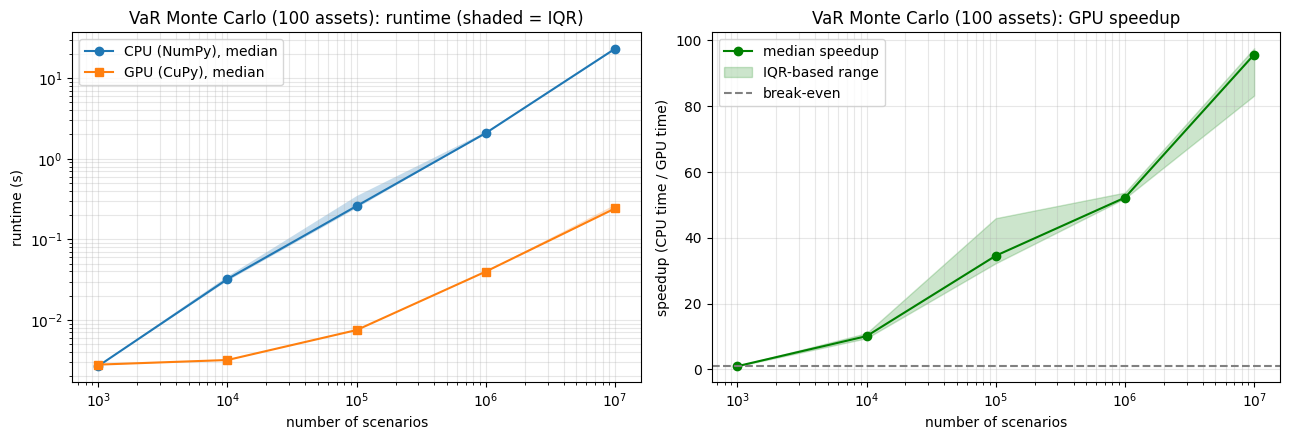

In [8]:
def plot_scaling(df, xcol, xlabel, title):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ax[0].loglog(df[xcol], df["cpu_s"], "o-", label="CPU (NumPy), median")
    if "cpu_q1" in df:
        ax[0].fill_between(df[xcol], df["cpu_q1"], df["cpu_q3"], alpha=0.25)
    if "gpu_s" in df:
        ax[0].loglog(df[xcol], df["gpu_s"], "s-", label="GPU (CuPy), median")
        ax[0].fill_between(df[xcol], df["gpu_q1"], df["gpu_q3"], alpha=0.25)
    ax[0].set_xlabel(xlabel); ax[0].set_ylabel("runtime (s)"); ax[0].set_title(title + ": runtime (shaded = IQR)")
    ax[0].grid(True, which="both", alpha=0.3); ax[0].legend()
    if "speedup" in df:
        ax[1].semilogx(df[xcol], df["speedup"], "o-", color="green", label="median speedup")
        ax[1].fill_between(df[xcol], df["speedup_lo"], df["speedup_hi"], color="green", alpha=0.2, label="IQR-based range")
        ax[1].axhline(1, color="gray", ls="--", label="break-even")
        ax[1].set_xlabel(xlabel); ax[1].set_ylabel("speedup (CPU time / GPU time)")
        ax[1].set_title(title + ": GPU speedup"); ax[1].grid(True, which="both", alpha=0.3); ax[1].legend()
    else:
        ax[1].text(0.5, 0.5, "No GPU detected", ha="center"); ax[1].axis("off")
    plt.tight_layout(); plt.show()

plot_scaling(df_scen, "n_scen", "number of scenarios", f"VaR Monte Carlo ({N_ASSETS} assets)")

**How to read it:** the left plot is log-log, so the gap between the lines is the speedup. The right plot makes the break-even point visible: the left side shows where the GPU's fixed overheads dominate, the right side shows where its parallelism pays off. Shaded bands show the interquartile range across repeated runs; wide bands at small sizes are expected, since launch overhead and shared Colab resources dominate there.

### Experiment A2: kernel-only vs. end-to-end

The runs above exclude portfolio construction (a Cholesky factorization on the host) and the host-to-device copy of `L`, `mu`, `w`. That is reasonable when you reuse one portfolio for many simulations, but it reports **kernel throughput, not complete application latency**. Here the same sweep is repeated in `end_to_end` mode so the two can be compared directly.

  n_scen  kernel_speedup  end_to_end_speedup
    1000            0.96                2.88
   10000           10.10                4.84
  100000           34.55               28.44
 1000000           52.21               49.13
10000000           95.73               90.14


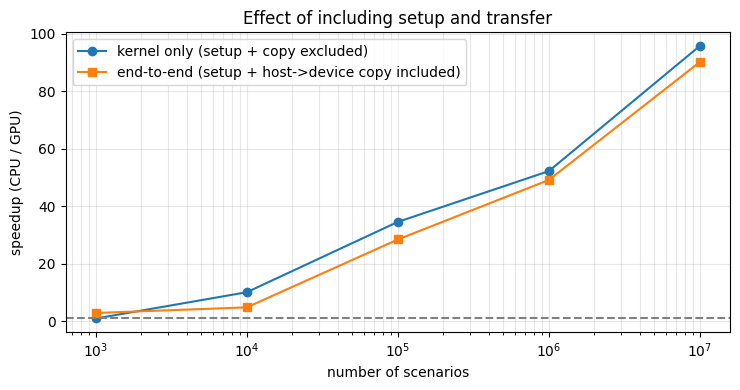

In [9]:
rows = [bench(10**e, N_ASSETS, mode="end_to_end") for e in range(3, MAX_EXP + 1)]
df_e2e = pd.DataFrame(rows)

if HAS_GPU:
    cmp = df_scen[["n_scen", "speedup"]].rename(columns={"speedup": "kernel_speedup"}).merge(
          df_e2e[["n_scen", "speedup"]].rename(columns={"speedup": "end_to_end_speedup"}), on="n_scen")
    print(cmp.round(2).to_string(index=False))
    fig, ax = plt.subplots(figsize=(7.5, 4))
    ax.semilogx(cmp["n_scen"], cmp["kernel_speedup"], "o-", label="kernel only (setup + copy excluded)")
    ax.semilogx(cmp["n_scen"], cmp["end_to_end_speedup"], "s-", label="end-to-end (setup + host->device copy included)")
    ax.axhline(1, color="gray", ls="--")
    ax.set_xlabel("number of scenarios"); ax.set_ylabel("speedup (CPU / GPU)")
    ax.set_title("Effect of including setup and transfer"); ax.grid(True, which="both", alpha=0.3); ax.legend()
    plt.tight_layout(); plt.show()
else:
    print(df_e2e[["n_scen", "cpu_s"]].round(4).to_string(index=False))

## 6. Experiment B: scale the number of assets
More assets means a larger matrix multiply (`scenarios x assets` times `assets x assets`). Matmul is what GPUs are built for, so larger matrices generally improve GPU utilization. But don't expect a perfectly monotonic curve: speedup also depends on matrix shape, memory pressure and how efficient the CPU's BLAS and the GPU's CUDA libraries are at each size.

  mode  n_scen  n_assets  horizon  reps   cpu_s  cpu_min  cpu_max  cpu_q1  cpu_q3  gpu_s  gpu_min  gpu_max  gpu_q1  gpu_q3  speedup  speedup_lo  speedup_hi
kernel 1000000        10        1     5  0.2448   0.2153   0.2729  0.2440  0.2487 0.0087   0.0085   0.0088  0.0087  0.0088  28.0951     27.7769     28.6274
kernel 1000000        50        1     5  1.0670   1.0577   1.0795  1.0635  1.0715 0.0265   0.0264   0.0265  0.0265  0.0265  40.3189     40.1543     40.4901
kernel 1000000       100        1     5  2.0947   2.0146   2.7501  2.0884  2.3291 0.0399   0.0398   0.0401  0.0399  0.0400  52.4767     52.2298     58.4367
kernel 1000000       250        1     5  6.2301   5.8409   6.4838  5.9656  6.3237 0.0764   0.0653   0.0957  0.0657  0.0955  81.4929     62.4918     96.2068
kernel 1000000       500        1     5 14.8022  14.4246  14.9227 14.5170 14.9169 0.1791   0.1772   0.2547  0.1790  0.1806  82.6526     80.3691     83.3532
kernel 1000000      1000        1     3 39.6961  39.5944  39.824

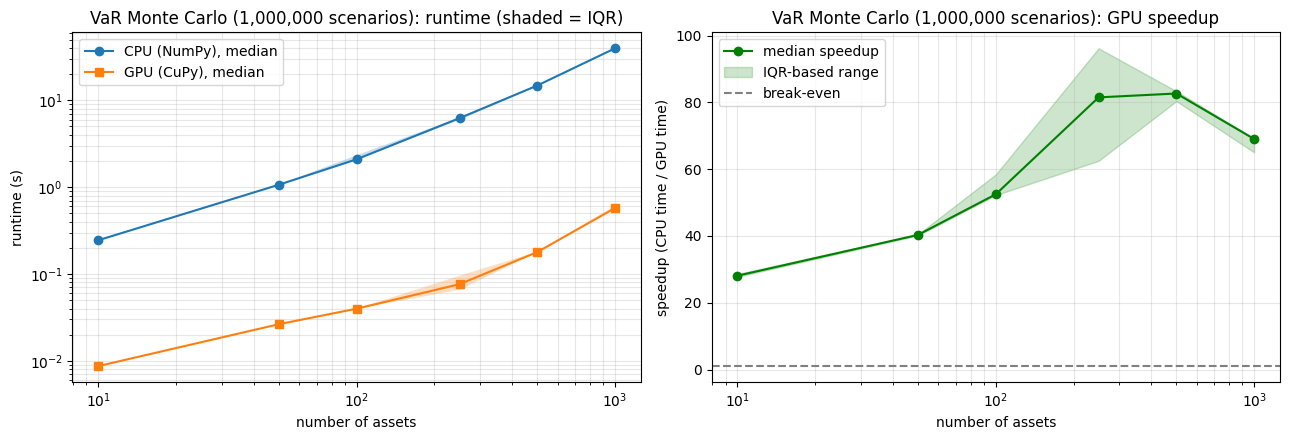

In [10]:
N_SCEN_B = 1_000_000
rows = [bench(N_SCEN_B, a) for a in [10, 50, 100, 250, 500, 1000]]
df_assets = pd.DataFrame(rows)
print(df_assets.round(4).to_string(index=False))
plot_scaling(df_assets, "n_assets", "number of assets", f"VaR Monte Carlo ({N_SCEN_B:,} scenarios)")

**Reading Experiment B:** larger workloads generally improve GPU utilization, but speedup is not guaranteed to keep rising with asset count. In one T4 run it was about 30x at 10 assets, peaked near 73x at 250 assets, then eased to about 65x at 500 and 53x at 1,000. Treat that as an example of the shape, not a prediction: your numbers will differ with the CPU, GPU and library versions.

## 7. Experiment C: multi-day paths
Simulating a 10-day or 250-day horizon multiplies the amount of work per scenario by the horizon length. (Scenarios are reduced here to keep the CPU run reasonable.)

  mode  n_scen  n_assets  horizon  reps   cpu_s  cpu_min  cpu_max  cpu_q1  cpu_q3  gpu_s  gpu_min  gpu_max  gpu_q1  gpu_q3  speedup  speedup_lo  speedup_hi
kernel  100000       100        1     5  0.2500   0.2130   0.2537  0.2499  0.2535 0.0076   0.0075   0.0076  0.0075  0.0076  33.0820     33.0640     33.6041
kernel  100000       100       10     5  2.0851   2.0797   2.9565  2.0828  2.2584 0.0286   0.0285   0.0287  0.0286  0.0286  72.9653     72.8395     79.0390
kernel  100000       100       50     5 11.1901  10.8276  11.3291 10.8326 11.2030 0.0988   0.0953   0.1219  0.0978  0.1096 113.2925     98.8305    114.6056
kernel  100000       100      250     3 56.3896  55.4298  56.4776 55.9097 56.4336 0.4808   0.4767   0.5041  0.4787  0.4925 117.2803    113.5318    117.8800


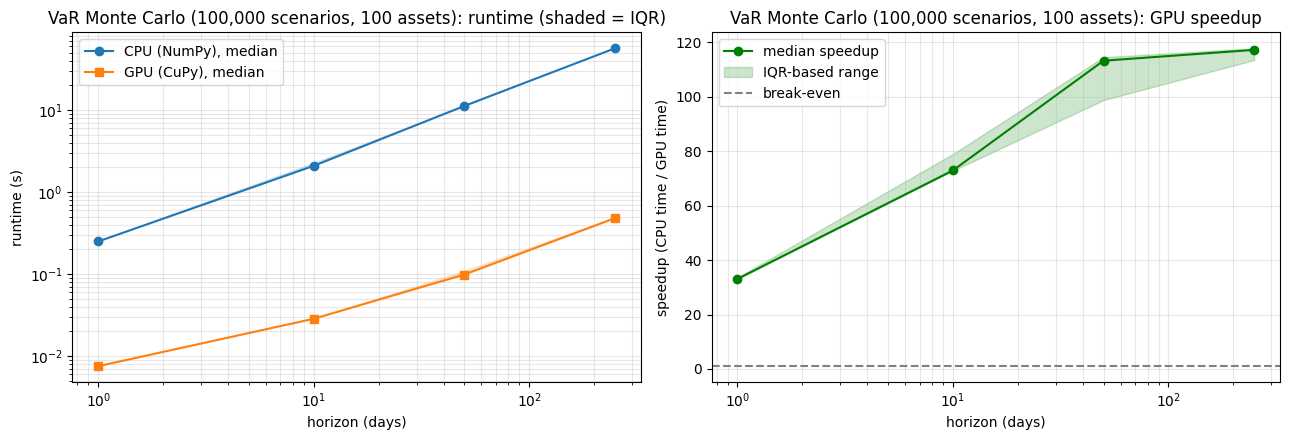

In [11]:
N_SCEN_C, A_C = 100_000, 100
rows = [bench(N_SCEN_C, A_C, horizon=h) for h in [1, 10, 50, 250]]
df_h = pd.DataFrame(rows)
print(df_h.round(4).to_string(index=False))
plot_scaling(df_h, "horizon", "horizon (days)", f"VaR Monte Carlo ({N_SCEN_C:,} scenarios, {A_C} assets)")

## 8. Where the transfer cost bites

In the experiments above, the only inputs are a small covariance factor and weights, and random numbers are generated **on the device**, so almost no data crosses the PCIe bus.

Many real pipelines instead start with data on the host (e.g. historical scenario matrices). Then host-to-device copy time becomes part of the cost. Here we measure it directly.

Data size                 : 800 MB
Host -> device copy      :    218.6 ms
GPU compute only         :     35.3 ms
GPU end-to-end (copy+compute):    253.9 ms
CPU (NumPy)              :   1836.5 ms

Speedup compute-only: 52.0x | end-to-end: 7.2x


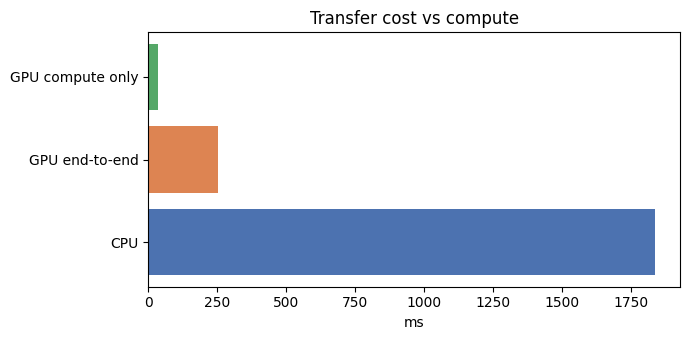

In [12]:
if HAS_GPU:
    n_scen, n_assets = 2_000_000, 100
    L, mu, w = make_portfolio(n_assets)
    H = np.random.default_rng(1).standard_normal((n_scen, n_assets)).astype(np.float32)   # "historical" shocks on host
    Lg, mug, wg = cp.asarray(L), cp.asarray(mu), cp.asarray(w)

    def gpu_compute_only(Hg):
        R = Hg @ Lg.T + mug
        return float(-cp.quantile(cp.expm1(R) @ wg, 0.01))

    Hg = cp.asarray(H); sync(); gpu_compute_only(Hg)          # warm-up

    t_h2d = timeit(lambda: cp.asarray(H))
    t_comp = timeit(lambda: gpu_compute_only(Hg))
    t_cpu = timeit(lambda: float(-np.quantile(np.expm1(H @ L.T + mu) @ w, 0.01)))
    t_e2e = t_h2d + t_comp

    print(f"Data size                 : {H.nbytes/1e6:.0f} MB")
    print(f"Host -> device copy      : {t_h2d*1e3:8.1f} ms")
    print(f"GPU compute only         : {t_comp*1e3:8.1f} ms")
    print(f"GPU end-to-end (copy+compute): {t_e2e*1e3:8.1f} ms")
    print(f"CPU (NumPy)              : {t_cpu*1e3:8.1f} ms")
    print(f"\nSpeedup compute-only: {t_cpu/t_comp:.1f}x | end-to-end: {t_cpu/t_e2e:.1f}x")

    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.barh(["CPU", "GPU end-to-end", "GPU compute only"], [t_cpu*1e3, t_e2e*1e3, t_comp*1e3], color=["#4c72b0", "#dd8452", "#55a868"])
    ax.set_xlabel("ms"); ax.set_title("Transfer cost vs compute"); plt.tight_layout(); plt.show()
else:
    print("Skipped (no GPU).")

## 9. Precision: float32 vs float64

Consumer and cloud-inference GPUs (like the Colab T4) have far more float32 throughput than float64, often by 30x or more. CPUs lose only about 2x going to float64. So the dtype you choose changes the comparison. A fair benchmark compares like with like, and this cell shows the effect.

In [13]:
rows = []
for dt, name in [(np.float32, "float32"), (np.float64, "float64")]:
    r = bench(1_000_000, 100, dtype=dt); r["dtype"] = name; rows.append(r)
df_prec = pd.DataFrame(rows)[["dtype", "cpu_s", "gpu_s", "speedup"] if HAS_GPU else ["dtype", "cpu_s"]]
print(df_prec.round(4).to_string(index=False))

  dtype  cpu_s  gpu_s  speedup
float32 2.0707 0.0406  51.0508
float64 3.0999 0.1882  16.4702


## 10. Summary table

In [14]:
summary = df_scen.copy()
summary["n_scen"] = summary["n_scen"].map(lambda x: f"{x:,}")
cols = ["n_scen", "cpu_s"] + (["gpu_s", "speedup"] if HAS_GPU else [])
print(summary[cols].round(4).to_string(index=False))
if HAS_GPU:
    best = df_scen.loc[df_scen["speedup"].idxmax()]
    print(f"\nPeak speedup in Experiment A: {best['speedup']:.1f}x at {int(best['n_scen']):,} scenarios")

    n_scen   cpu_s  gpu_s  speedup
     1,000  0.0027 0.0028   0.9620
    10,000  0.0322 0.0032  10.0999
   100,000  0.2594 0.0075  34.5475
 1,000,000  2.0838 0.0399  52.2145
10,000,000 23.1459 0.2418  95.7308

Peak speedup in Experiment A: 95.7x at 10,000,000 scenarios


## 11. Takeaways

- **The algorithm didn't change.** The same function ran on both devices; only `xp` changed.
- **GPUs win on throughput, not latency.** At small sizes, launch and synchronization overhead make the GPU slower or equal. At millions of scenarios it wins decisively.
- **More parallel work generally means a bigger win.** Speedup generally improves with workload size, subject to matrix shape, memory pressure and BLAS/CUDA efficiency. It is not guaranteed to rise monotonically (it can peak at a mid-sized asset count and then ease off).
- **Data movement is the hidden cost.** Generating random numbers on the device avoided PCIe transfers. When inputs start on the host, copy time can eat much of the gain, and Experiment A2 shows how including setup and the host-to-device copy changes the speedup.
- **Precision matters.** float64 narrows the gap on GPUs with weak fp64 throughput.

**Why it works:** a CPU has a few powerful cores tuned for low latency and branching code. A GPU has thousands of simpler cores tuned for running the *same* operation over huge amounts of independent data, which is exactly what Monte Carlo is.

**Caveats for an honest benchmark:** the CPU baseline here is NumPy with multithreaded BLAS on a small number of Colab cores. A many-core server CPU narrows the gap, and so does a hand-tuned multithreaded implementation. Also, timings vary with hardware and shared Colab resources, so quote the GPU model, CPU core count and the spread across repeats alongside any speedup number. Timings exclude one-time CUDA initialization and kernel compilation (handled by warm-up).

### Ideas to extend
- Add a **Numba `@njit(parallel=True)`** CPU version as a stronger baseline
- Try **PyTorch CUDA** and compare against CuPy
- Add **antithetic variates** or **quasi-random (Sobol)** sampling to reduce variance, and show variance vs. runtime
- Price an option portfolio inside each scenario to make the per-scenario work heavier